95% on log transform is different depending on base, so have both answers

why is transforming not p-hacking?

ideas for students interesting in bayesian stars (eg youtube, packages)


# Class 10: Significance tests

This class notebook is designed to let you practice significance testing. The datasets are small and uncomplicated compared to the project datasets. This is so that you can practice without the additional burden of cleaning and manipulating large, messy datasets. 

There are five questions covering some of the most common significance tests that you will come across in your studies

1. **Two-sample t-test**: When you want to compare the means of a numerical variable across two independent groups.
2. **Shapiro-Wilk test**: When your want to see if your data is compatible with being normally distributed.
3. **Pearson correlation test**: When you want to examine the correlation between two numerical variables
4. **Linear regression**: When you want to examine the numerical relationship between two numerical variables, e.g., "How does a change in X affect Y?" where X and Y are numerical variables.
5. **Anova**: When you want to compare the means of a numerical variable across three or more independent groups.

Everything you need to complete this notebook is covered in this notebook.

<div class="alert alert-info">
The answers to the questions below are given in blue boxes. These are there to help you write the correct code.
</div>

## Imports

Run the code cell below to import the necessary modules.

In [1]:
%matplotlib inline
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import t, ttest_ind, shapiro, pearsonr, linregress
from statsmodels.stats.oneway import anova_oneway
from interactive_plots import cor_coef_demo

# **Question 1**: Did ground finch beak depths evolve on the Galápagos islands between 1976 and 1978?

Let's start with the most commonly used statistical test; the two-sample *t*-test. If you took Biology 1A: Variation last year you will have used a *t*-test to analyse two-spot ladybird sizes and *Pseudomonas fluorescens* fitness.

A two-sample *t*-test is used when you want to compare the means of a numerical response variable between two groups of a categorical explanatory variable.

Let's return to the ground finch evolution example we looked at on Monday in which we estimated the change in beak depth before and after a drought.

To recap, Peter and Rosemary Grant and their colleagues have studied Galápagos finch species every year since 1976. One such species is the medium ground finch on the Galápagos island of Daphne Major.
<div>
<img src="Images/ground_finch.jpg" width='30%' title="Judy Gallagher CC BY 2.0"/>
</div>

The medium ground finch feeds on seeds. The finches have inherited variation in beak shape with some individuals having wide, deep beaks and others having thinner, shallower beaks. Large-beaked birds feed more efficiently on large, hard seeds, whereas smaller-beaked birds feed more efficiently on small, soft seeds. 

During 1977 a drought altered vegetation on the island. After the drought the number of seeds declined dramatically. The decline was greater in small, soft seeds than in large, hard seeds. Therefore, the Grants and colleagues hypothesised that large-beaked birds were better able to survive the drought than the small-beaked birds. 

As beak size is inherited from parent to offspring the theory of natural selection predicts that the drought would cause selection for finches with larger beaks. 

In other words, the theory of natural selection makes a prediction: that beak sizes, on average, will be different before and after the 1977 drought. We can test this prediction by comparing average beak sizes of medium ground finches on Daphne Major before (1976) and after (1978) the 1977 drought.

On Monday you worked out that mean beak depths differed by 0.49 ± 0.15 mm (mean ± SEM), i.e., about half a millimetre with a precision of a little more than a tenth of a millimetre. As an alternative you also calculated a 95% confidence interval (CI) of [0.19, 0.80] millimetres on the mean difference. Remember both the standard error of the mean and the 95% CI are both measures of the precision of your estimate.

Having estimated the difference in the means, our next question is this: 

<div class="alert alert-success">

How compatible are the data with the null hypothesis that mean beak depths did not differ between 1976 and 1978.

</div>


This is what you are going to do now.


The beak depths (in mm) collected by the Grants are in the file `../Datasets/finches beak depth.csv`.

---

- As you did on Monday, read in the dataset and print it out to see what it looks like. You may want to copy your code from Monday's notebook question 2 and paste it into this notebook. [Click here](Class_9_answers.ipynb) to open that notebook.

In [2]:
beaks = pd.read_csv('../Datasets/finches beak depth.csv')
beaks

,year,depth
0,1976,9.4
1,1976,10.3
2,1976,11.2
3,1976,9.2
4,1976,10.2
...,...,...
130,1978,10.2
131,1978,8.9
132,1978,11.2
133,1978,10.1


- Use an appropriate graph to visually compare beak depths between 1976 and 1978.

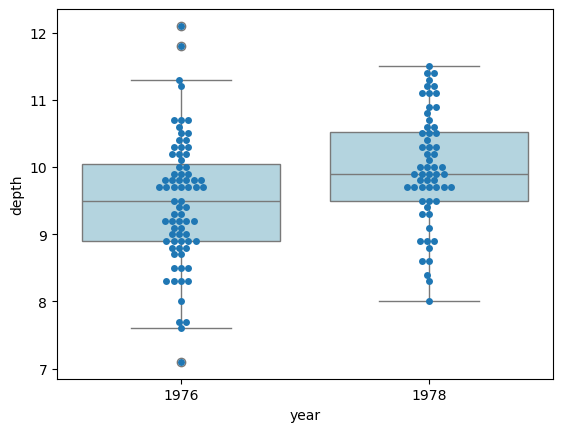

In [3]:
# A swarm plot combined with a box plot to show the distribution of beak depths across years is a good choice. The swarm plot will show individual data points, while the box plot will summarize the distribution with quartiles and outliers.

sns.swarmplot(data=beaks, x='year', y='depth')
sns.boxplot(data=beaks, x='year', y='depth', color='lightblue');

- The DataFrame has two columns called `year` and `depth`. To run a *t*-test you need to split your data into two subsets corresponding to the two samples: the 1976 sample and the 1978 sample. We did this on Monday, do the same again here.

In [4]:
beaks_1976 = beaks.query('year == 1976')
beaks_1978 = beaks.query('year == 1978')

The code to run a *t*-test is very simple:

```python
from scipy.stats import ttest_ind

test = ttest_ind(sample1['response variable'], sample2['response variable'])

print(f'degrees of freedom = {test.df:.0f}')
print(f't-statistic = {test.statistic:.2g}')
print(f'P = {test.pvalue:.2g}')

ci = test.confidence_interval()
print(f'95% CI = [{ci.low:.2g}, {ci.high:.2f}] mm')
```

- `sample1` is the DataFrame of the first sample (e.g, 1978)
- `sample2` is the DataFrame of the second sample (e.g., 1976).
- `'response variable'` is the name of the numerical response variable (e.g., `'depth'`.)

After running the *t*-test we print out the following information:

- `test.df` is the test's degrees of freedom. For the *t*-test this is the total number of observations minus 2. It's actual value is not particularly important for us, but conventionally it should always be reported when writing up your analysis in a report or poster.
- `test.statistic` is the *t*-statistic (which is why it's called a *t*-test). It's actual value is not particularly important for us, but conventionally it should always be reported when writing up your analysis in a report or poster.
- `test.pvalue` is the value of *P* for the test, i.e., the compatibility of the data with the null hypothesis.
- `test.confidence_interval()` returns the low and high bounds of the 95% CI of the difference between means. This is handy as you don't need to calculate the 95% CI yourself as we did on Monday.

---

- Perform a two-sample *t*-test on the beak depth samples to calculate their compatibility with the null hypothesis that mean beak depths do not differ between 1976 and 1978.


<div class="alert alert-info">

Answer

- degrees of freedom = 133
- *t*-statistic = 3.2
- *P* = 0.0019
- 95% CI = [0.19, 0.80] mm

</div>


In [5]:
test = ttest_ind(beaks_1978['depth'], beaks_1976['depth'])
print(f'degrees of freedom = {test.df:.0f}')
print(f't-statistic = {test.statistic:.2g}')
print(f'P = {test.pvalue:.2g}')

ci = test.confidence_interval()
print(f'95% CI = [{ci.low:.2g}, {ci.high:.2f}] mm')

degrees of freedom = 133
t-statistic = 3.2
P = 0.0019
95% CI = [0.19, 0.80] mm


Note that the value of *t* can be positive or negative depending on which year's data comes first in the call to `ttest_ind`. This does not affect the value of *P*.

---

- What do you conclude about the difference in ground finch beak depths between 1976 and 1978?

> The data are incompatible with the null hypothesis that mean beak depths differed between 1976 and 1978.
>
> There is a significant difference of 0.49 mm (95% CI [0.19, 0.80] mm) in ground finch beak depths between 1976 and 1978 ($t_{133}=3.2$, $p=0.002$).

Does this result prove that the greater reduction is small, soft seeds during the 1977 drought caused a change in ground finch mean beak depths? The short answer is no.

All you've shown is that there is evidence that mean beak depths differed between 1976 and 1978. In other words, the difference of 0.49 mm is unlikely random chance due to sampling error, and is more likely due to some real difference between the two years.

If the difference between mean beak depths is actually something real and not random chance, what has caused that difference? Again we cannot be certain. It could be due to the drought reducing the availability of small, soft seeds, but it may be due to something else that we are unaware of and therefore haven't measured. 

This is a problem with observational studies like this one. You are absolutely not allowed to conclude that a change in one thing **caused** a change in another thing. What you can conclude, however, is that a change in one thing is **correlated** with a change in another thing.  

For the ground finches, we are not allowed to conclude that the greater reduction in small, soft seeds during the 1977 drought **caused** the change in ground finch mean beak depths. Another explanation for the data might be that smaller beaked ground finches were slowly being out-competed by larger beaked ground finches over many years before the drought in 1977. The drought had no impact on the change in beak depths. Therefore, we can only conclude that the data are incompatible with the null hypothesis that beak depths no not differ between 1976 and 1978. That is all.

The only way to determine if a change in one thing causes a change in another thing is to do an **experimental** study in which the researcher manipulates the explanatory variable and records changes in the response variable. For example, manipulating temperature, or humidity, or soil pH, or fertiliser quality to examine changes in tomato plant growth rate. If tomato plants grow faster at pH 7 and slower at pH 6 then we can conclude that pH **causes** changes in tomato plant growth rate.

<div class="alert alert-success">

Concepts to take away from this question.

1. A two sample *t*-test is the most common statistical test. Use it when you want to compare the means of a numerical response variable between two groups of a categorical explanatory variable. 
3. The null hypothesis of a *t*-test is that the means do not differ between the two groups.
2. A *t*-test answers the question, how compatible are the data with the null hypothesis of no difference or no change or no effect between the two groups?
4. The value of *P* that results from a *t*-test is a measure of the compatibility of the data with the null hypothesis. The higher the value of *P* the more compatible the data are with the null hypothesis.
5. Conventionally, *P* \< 0.05 is considered "statistically significant", and P > 0.05 is considered "not statistically significant". But this arbitrary convention applied to your data has no bearing whatsoever on whether the null hypothesis is true or not. In other words, just because you find *P* < 0.05, does not imply that a real difference exists between your groups. Or just because you find P > 0.05 does not imply that no difference exists.
7. When writing up a *t*-test in a report or poster always report
    - the observed difference in the means with either the standard error in the mean or the 95% CI.
    - the value of the *t*-statistic and the degrees of freedom,
    - the value of *P*,
    - e.g., 
        > A significant difference of 0.49 mm (95% CI [0.19, 0.80] mm) was found in ground finch beak depths between 1976 and 1978 ($t_{133}=3.2$, $P=0.002$).
8. Observational studies can only provide evidence for a correlation between the explanatory and response variables. They do not provide evidence that a change in the explanatory variable causes a change in the response variable. 
9. Experimental studies that manipulate the explanatory variable can provide evidence that a change in the explanatory variable causes a change in the response variable. 

</div>


# **Question 2:** Are my data normally distributed?

Whenever we do a statistical test we need to make sure our data meet certain conditions. One of the conditions for a *t*-test is that the data are approximately normally distributed. In the last example, plots of ground finch beak depths look like they meet this condition, so applying a *t*-test is fine. 

But what if our data don't look normally distributed? How do we tell if they are or not? And what can we do if they are not? 

## Doubling time of *Plasmodium chabaudi* in two mice strains

<div>
<img src="Images/malaria mouse.jpg" width='40%'/>
</div>

*Plasmodium chabaudi* is a malaria parasite that infects rodents in Africa. It is used extensively in labs around the world as its pathology in mice resembles that of human malaria such as anaemia, hypoglycaemia, changes in body temperature, weight loss and death. 

In one study, researchers measured the doubling time of *P. chabaudi* in two laboratory mouse strains, celled BALB/c and C57Bl/6, to examine if the parasite grew at different rates in the two strains.

The doubling times (in hours) in 40 mice collected by the researchers are in the file `../Datasets/chabaudi.csv`.

---

- Read in the dataset and print it out to see what it looks like.

In [6]:
ch = pd.read_csv('../Datasets/chabaudi.csv')
ch

,strain,time
0,BALBc,23.8
1,BALBc,6.0
2,BALBc,5.0
3,BALBc,13.5
4,BALBc,7.8
5,BALBc,15.8
6,BALBc,5.1
7,BALBc,10.3
8,BALBc,9.0
9,BALBc,6.0


You'll see two columns and 40 rows. Each row is an individual mouse. The strain of each mouse is given and the doubling time of *P. chabaudi* in hours in each mouse.

---

- Use an appropriate **histogram** to examine the shapes of the doubling time distributions for each mouse strain.

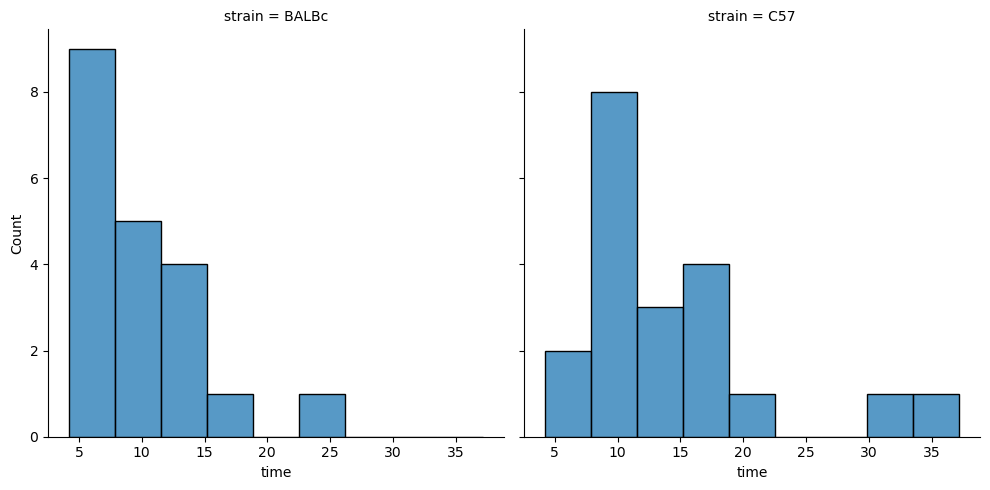

In [7]:
sns.displot(data=ch, col='strain', x='time');

You should see that the doubling time distribution for BALBc mice does not look normally distributed at all. Instead it looks right-skewed, i.e., the distribution is not symmetrical about the mean and the data tail off slowly to the right. The C57 doubling times are trickier, they could be normally distributed or right skewed—it's hard to tell given how little data there are.

Data must be approximately normally distributed to be able to use a *t*-test on them.

So before we apply a *t*-test we need to determine if the data are compatible with being normally distributed. We can do this using what's called a Shapiro-Wilk tests, named after the authors who published it in 1965.

The Shapiro-Wilk test is a statistical test, so it has a null hypothesis. And the null hypothesis is that the data are normally distributed. This means the value *P* of the Shapiro-Wilk test is a measure of the compatibility of the data being normally distributed.

In other words, if *P* is high the data are compatible with being normally distributed, and if *P* is low the data are incompatible with being normally distributed. 

---

- If you haven't done so already, split the data into two subsets, one for each mouse strain.

In [8]:
balbc = ch.query('strain == "BALBc"')
c57 = ch.query('strain == "C57"')

- Now perform two Shapiro-Wilk tests on doubling times, one for each mouse strain. 

The code for the Shapiro-Wilk test is

```python
from scipy.stats import shapiro

test = shapiro(sample['response variable'])

print(f'P = {test.pvalue:.2g}')
```

<div class="alert alert-info">

Answer

- BALBc: P = 0.019
- C57: P = 0.0018

</div>


In [9]:
test = shapiro(balbc['time'])
print(f'BALBc: P = {test.pvalue:.2g}')
test = shapiro(c57['time'])
print(f'C57: P = {test.pvalue:.2g}')

BALBc: P = 0.019
C57: P = 0.0018


The *P* values for both strains are small and statistically significant. Which means there is evidence the data are incompatible with the null hypothesis of being normally distributed. 

In other words, the data are probably not normally distributed. Which means we should not use a *t*-test to compare mean doubling times between BALBc and C57 mice with the data is their current form.

When faced with this situation, the first thing to try is log-transforming the data. The idea behind the log-transform is that it squashes the larger values toward the smaller values as shown in this Table.

*x* | log<sub>10</sub>(*x*)
--: | --:
1000 | 3
100 | 2
10 | 1
1 | 0

The difference between 1,000 and 1 is 999, but the difference between log<sub>10</sub>(1,000) and log<sub>10</sub>(1) is just 3.

In terms of the *P. chabaudi* data, the log-transform brings the large doubling times in the 20s and 30s closer to the main peak of around 10 hours.

---

- Create a new column in your DataFrame that contains the log of the doubling time. You've seen how to do this in the [Class_3 notebook](../Week_02/Class_3.ipynb). 

<div class="alert alert-success">

Note that it makes no difference which base of log you use: `np.log()` takes the log to base *e* whereas `np.log10()` takes the log to base 10. Taking log to base 10 is easier to interpret as log<sub>10</sub>(10) = 1, log<sub>10</sub>(100) = 2, etc. 

</div>

In [10]:
ch['log_time'] = np.log10(ch['time'])

- Replot the data but now using the log doubling time.

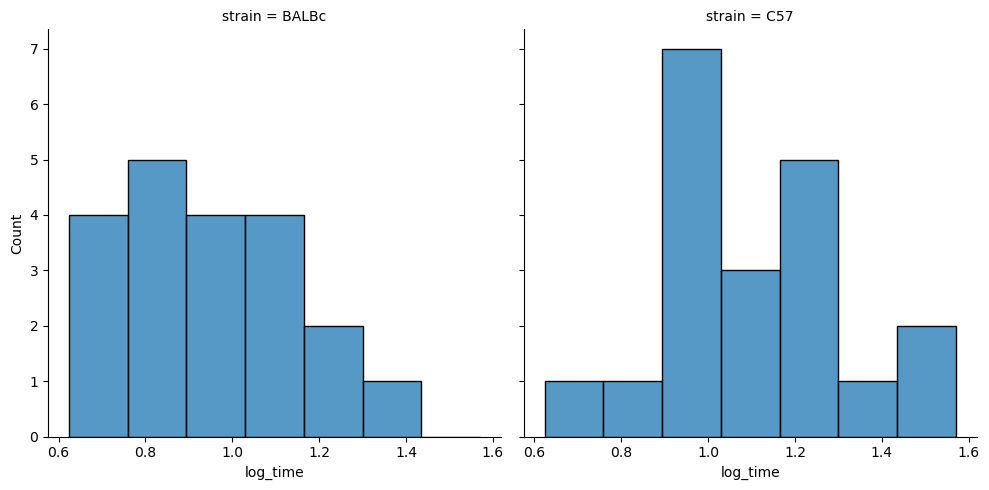

In [11]:
sns.displot(data=ch, col='strain', x='log_time');

You should see that the logged doubling times are more "normal" like.

---

- Now perform Shapiro-Wilk tests on logged doubling times for each mouse strain separately. 

Remember to split your data into two subsets again as you've just added a new column to your DataFrame.

<div class="alert alert-info">

Answer

- BALBc: P = 0.93
- C57: P = 0.53

</div>


In [12]:
balbc = ch.query('strain == "BALBc"')
c57 = ch.query('strain == "C57"')

test = shapiro(balbc['log_time'])
print(f'BALBc: P = {test.pvalue:.2g}')
test = shapiro(c57['log_time'])
print(f'C57: P = {test.pvalue:.2g}')

BALBc: P = 0.93
C57: P = 0.53


The *P* values for both strains are large and "not significant". Which means the log-transformed data are compatible with being normally distributed. They may not be, but you have no evidence they aren't. 

Which all means we can now use a *t*-test to compare mean log-doubling times between BALBc and C57 mice.

<div class="alert alert-success">

Transforming data in this way is legitimate. It is not one of the dubious tricks that researchers use in the search for significance.
</div>

---

- Perform a two-sample *t*-test on the log doubling times to calculate their compatibility with the null hypothesis that mean doubling times do not differ between BALBc and C57 mice.

<div class="alert alert-info">

Answer

- degrees of freedom = 38
- *t*-statistic = 2.3
- *P* = 0.029
- 95% CI = [0.016, 0.278]

</div>

In [13]:
test = ttest_ind(c57['log_time'], balbc['log_time'])
print(f'degrees of freedom = {test.df:.0f}')
print(f't-statistic = {test.statistic:.1f}')
print(f'P = {test.pvalue:.3f}')

ci = test.confidence_interval()
print(f'95% CI = [{ci.low:.3f}, {ci.high:.3f}]')

degrees of freedom = 38
t-statistic = 2.3
P = 0.029
95% CI = [0.016, 0.278]


You're not quite finished yet because you also need to report the 95% CI for the difference in doubling times. 

The 95% CI of [0.016, 0.278] returned by the *t*-test is the mean difference in **log** doubling times. We want the non-logged mean difference in hours. This is easily fixed by back-transforming.

- If you used log to base *e* you need to use `np.exp(x)` to back transform.
- If you used log to base 10 you need to use `10**x` to back transform.

where `x` is the mean difference in log doubling time, or the low or high bound of the 95% CI.

---

- Back-transform to find 
    - the mean difference in doubling times in hours (You'll first have to find the mean difference in log doubling times if you haven't already done so)
    - the 95% CI of mean difference in doubling times

<div class="alert alert-info">

Answer

- Mean difference: 1.4 hours
- 95% CI of difference: [1.0, 1.9] hours
</div>

In [14]:
d = c57['log_time'].mean() - balbc['log_time'].mean()
print(f'Mean difference: {10**d:.2g} hours')
print(f'95% CI of difference: [{10**ci.low:.1f}, {10**ci.high:.1f}] hours')


Mean difference: 1.4 hours
95% CI of difference: [1.0, 1.9] hours


- What do you conclude about the difference in malaria parasite doubling times between BALBc and C57 mice?

> *P. chabaudi* doubling times in C57 mice are 1.4 hours longer (95% CI [1.0, 1.9] h) than in BALBc mice ($t_{38}=2.3$, $p=0.029$).

<div class="alert alert-success">

Concepts to take away from this question.

1. Most statistical tests come with certain conditions on your data. To be able to use the two-sample *t*-test, your data needs to be approximately normally distributed.
2. The Shapiro-Wilk test can indicate if your data are compatible or not with being normally distributed.
3. If your data are incompatible with being normally distributed you can transform your data to make it so. There are several different transformations, but the log-transformation is the most common.
4. Once the statistical test has been completed, the estimated mean transformed difference and its 95% CI need to be back-transformed for reporting.
</div>


# **Question 3**: Are arrival times of gannet breeding pairs correlated?

<div>
<img src="Images/bassrock1.jpeg" width='40%'/>
</div>

Bass Rock is a small island in the Firth of Forth about a 45 minute train journey from Edinburgh. It plays host to the world's largest colony of northern gannets. Described by David Attenborough as "one of the wildlife wonders of the world".

Northern gannets mate for life. And every March they return to the island to breed, laying a single egg.

Researchers from Glasgow University recorded the arrival dates of ten breeding pairs in a single season. They were interested in seeing if the arrival dates of pairs were correlated or not. That is, did knowing the arrival date of one of the pair allow them to predict the approximate arrival date of the mate. Or did the birds arrive on random dates?

The arrival days, relative to 1st March are in the file `../Datasets/gannets.csv`.

---

- Read in the dataset and print it out to see what it looks like.

In [15]:
gannets = pd.read_csv('../Datasets/gannets.csv')
gannets

,pair,male,female
0,1,19,22
1,2,20,28
2,3,23,17
3,4,17,21
4,5,15,18
5,6,24,23
6,7,11,17
7,8,21,25
8,9,20,24
9,10,20,22


There are three columns, an pair-ID column which can be ignored. The arrival date of males and the arrival date of females.

---

- Use an appropriate graph to visually examine the relationship between these two numerical variables.

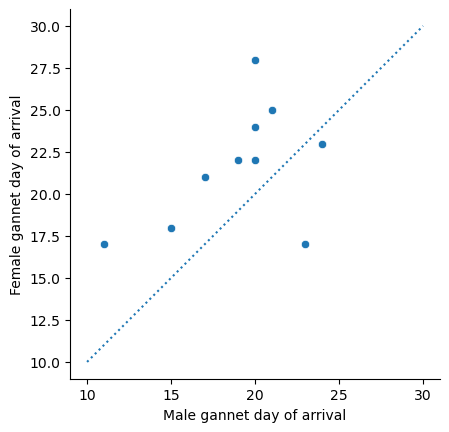

In [16]:
ax = sns.scatterplot(data=gannets, x='male', y='female')
ax.plot([10, 30], [10, 30], ls=':')
ax.set_xlabel('Male gannet day of arrival')
ax.set_ylabel('Female gannet day of arrival')
ax.set_aspect('equal')
sns.despine()

Before doing the statistical test, and based on your plot, would you consider that male and female gannet arrival days are correlated?

What does it mean when two numerical variables are correlated? It means that changes in one variable tend to correspond with changes in the other. Correlation measures the **strength** and **direction** of this relationship, but it does not mean that one variable causes the other to change.

If you run the interactive plot in the code cell below, you can use the slider to change the strength and direction of the correlation between two numerical variables.

In [ ]:
%matplotlib widget
cor_coef_demo();

In [18]:
# RUN THIS CODE OTHERWISE ANY FURTHER PLOTS YOU MAKE WON'T SHOW. THIS IS A QUIRK OF JUPYTER NOTEBOOKS.
%matplotlib inline
plt.close()

The symbol *r* in the interactive plot is called the correlation coefficient. *r* can have a value from -1 to 1. 

Negative *r* means the variables are negatively correlated: an increase in one variable corresponds to a decrease in the other variable. Positive *r* means the variables are positively correlated: an increase in one variable corresponds to an increase in the other variable.

When *r* equals -1 the two variables are perfectly negatively correlated: the data form a straight line from the top left to the bottom right. When *r* equals 1 the two variables are perfectly positively correlated: the data form a straight line from the bottom left to the top right. And when *r* equals 0 the two variables are not correlated at all, which means a change in one variable shows no corresponding change in the other variable.

The **Pearson correlation test** is used to measure the compatibility of the data with the null hypothesis of no correlation between the two variables. The code to do this is

```python
from scipy.stats import pearsonr

test = pearsonr(variable1, variable2)
print(f'r-statistic = {test.statistic:.2g}')
print(f'P = {test.pvalue:.2g}')

ci = test.confidence_interval()
print(f'95% CI = [{ci.low:.2g}, {ci.high:.2g}] days')
```

where `variable1` and `variable2` are the data for the two variables. Also note that there is no degree of freedom for the correlation test.

---

- Perform a Pearson correlation test on the male and female gannet arrival times to calculate their compatibility with the null hypothesis that arrival times are not correlated.

Note that you don't need to split the data into subsets as you did previously because the data are already in two columns in the DataFrame. So you just need to use the column names to refer to the data, e.g., `df['male']` and `df['female']`.

<div class="alert alert-info">

Answer

- *r*-statistic = 0.46
- *P* = 0.18
- 95% CI = [-0.24, 0.85]

</div>

In [19]:
test = pearsonr(gannets['female'], gannets['male'])
print(f'r-statistic = {test.statistic:.2g}')
print(f'P = {test.pvalue:.2g}')

ci = test.confidence_interval()
print(f'95% CI = [{ci.low:.2g}, {ci.high:.2f}]')


r-statistic = 0.46
P = 0.18
95% CI = [-0.24, 0.85]


- What do you conclude about the correlation of arrival times of male and female gannets?

> Male and female gannet arrival times are compatible with the null hypothesis of no correlation ($r=0.46$, $p=0.18$, 95%CI: [-0.24, 0.85]).

Notice that the 95% CI contains zero as it goes from -0.24 to 0.85. So the 95% CI contains the null hypothesis of no (i.e., zero) correlation. This is always the case: If a 95% CI contains zero then the value of *P* will always be greater than 0.05. Conversely, if a 95% CI does not contain zero then the value of *P* will always be less than 0.05. 

<div class="alert alert-success">

Concepts to take away from this question.

1. Correlation means that changes in one variable tends to correspond with changes in another variable. Correlation measures the **strength** and **direction** of this relationship.
2. If two variables are correlated, this does not imply that one **causes** a change in the other. There is a well-known saying: "Correlation does not imply causation".
3. The Pearson correlation test is used to measure the compatibility of the data with the null hypothesis of no correlation between two variables.
4. If a 95% CI contains zero then the value of *P* will always be greater than 0.05. Conversely, if a 95% CI does not contain zero then the value of *P* will always be less than 0.05. 

</div>


# **Question 4**: Do rattlesnake temperatures increase whilst eating?

<div>
<img src="Images/rattlesnake.jpg" width='40%'/>
</div>

Scientists wanted to know how much rattlesnake temperature changes when they are digesting meals of different sizes. They measured the weight of a meal relative to weight of each rattlesnake and the maximum change in temperature during digestion relative to pre-meal temperature.

If there is no relationship between temperature change and meal size, then a plot of temperature change against meal size would exhibit a flat line. A line, that is, with a slope of zero as sketched in the left panel if the figure below. Conversely, if there is a relationship between them such a plot would exhibit either a rising or a falling line. That is, a line with non-zero slope as sketched in the middle and right panels in the figure below.

<div>
<img src="Images/rattlesnake_slopes.png" width='80%'/>
</div>

The null hypothesis is the hypothesis of no difference or no change. So the null hypothesis is: The slope of the relationship between temperature change and meal size is zero.

The rattlesnake data are in the file `../Datasets/rattlesnakes.csv`

--- 


- Read in the dataset and print it out to see what it looks like.

In [20]:
rs = pd.read_csv('../Datasets/rattlesnakes.csv')
rs

,mealSize,tempChange
0,0.0,0.05
1,0.0,-0.05
2,0.0,-0.15
3,5.5,0.15
4,12.0,0.35
5,14.5,0.35
6,23.3,0.65
7,27.1,0.75
8,29.3,0.75
9,20.8,0.85


Variable names are "mealSize" and "tempChange". Both variables are continuous numerical variables. "mealSize" is the weight of the meal relative to each rattlesnake's weight recorded as a percentage. So a meal size of 50.4% means that the weight of the meal was half the weight of the rattlesnake. "tempChange" is measured in degrees Celsius.

Meal size is being manipulated by the researchers, so this is an experimental study. Which means that any changes in temperature are **caused** by eating a meal. 

"mealSize" is the explanatory variable and "tempChange" is the response variable.

---

- Use an appropriate graph to visually examine the relationship between meal size and change in temperature.

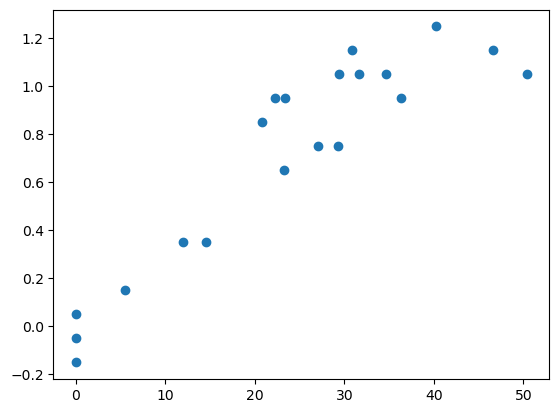

In [21]:
plt.scatter(rs['mealSize'], rs['tempChange']);

It should be obvious from plotting the data that manipulating meal size causes rattlesnake temperature to increase. In this case a statistical test to tell you that the relationship is "significant" is unnecessary. 

However, let's perform a statistical test to see how it is done.

We could perform a Pearson correlation test. But because meal size is being manipulated by the researchers and there is probably little uncertainty in the variable "mealSize" we can use linear regression instead.

The code to perform a linear regression is as follows:

```python
from scipy.stats import t, linregress

test = linregress(explanatory_variable, response_variable)

print(f'slope = {test.slope:.2g}')
print(f'standard error of slope = {test.stderr:.2g}')
print(f'P = {test.pvalue:.2g}')
```

where 
- `explanatory_variable` and `response_variable` are the two variables.

After running the linear regression we print out the following information:

- `test.slope` is the slope (or gradient) of the relationship. 
- `test.stderr` is the standard error of the slope, i.e., how precisely we can estimate it with the data we have.
- `test.pvalue` measures the compatibility of the data with the the null hypothesis of zero slope.

The units of `slope` are a little long-winded: ℃ per percent relative meal size.

---

- Perform a linear regression of meal size and temperature change.

<div class="alert alert-info">

Answer

- slope = 0.027
- standard error of slope = 0.0028
- *P* = 1.6 x 10<sup>-8</sup>

</div>

In [22]:
test = linregress(rs['mealSize'], rs['tempChange'])
print(f'slope = {test.slope:.2g}')
print(f'standard error of slope = {test.stderr:.2g}')
print(f'P = {test.pvalue:.2g}')

slope = 0.027
standard error of slope = 0.0028
P = 1.6e-08


Unfortunately, for some unknown reason, linregress does not automatically calculate a 95% CI on the slope. We have to do this manually. The formulae for the low and high bounds are the usual

- low bound = $\text{slope} - t_{n-1}\times\text{SE of slope}$
- high bound = $\text{slope} + t_{n-1}\times\text{SE of slope}$

where *n* is the number of observations.

---

- Calculate the 95% CI of the slope.

<div class="alert alert-info">

Answer

95% CI: [0.021, 0.033]

</div>

In [23]:
n = len(rs)
tn = t.ppf(0.975, df=n-1)
ci_low = test.slope - tn*test.stderr
ci_high = test.slope + tn*test.stderr
print(f'95% CI: [{ci_low:.2g}, {ci_high:.2g}]')


95% CI: [0.021, 0.033]


- What do you conclude about change in body temperature with relative meal size in rattlesnakes?

> There is very strong evidence that every 1% change in meal size relative to rattlesnake body weight causes a 0.027 ℃ (95% CI: [0.021, 0.033] ℃) change in body temperature (*P* = $2\times 10^{-8}$).

<div class="alert alert-success">

Concepts to take away from this question.

1. Use linear regression when you want to answer, "How does a change in X affect Y?"
2. Variables have distinct roles: X is the explanatory variable (also called a predictor or independent variable), and Y is the response variable (also called a dependent or outcome variable). 

</div>


# **Question 5:** How does caffeine in nectar affect visitation by pollinators?

<div>
<img src="Images/pollinators.jpg" width='50%' title=""/>
</div>

Flower nectar contains caffeine, but why? Researchers hypothesised that plants use caffeine to entice pollinators to feed from their nectar. They set up an experiment in which bees could feed from one of five sources of nectar, each with a different concentration of caffeine. Every 24 hours over five days they measured how much nectar was taken from each of the feeding sources. 

The data are in the file `../Datasets/nectar.csv`. 

---

- Read in the data and print it to see what it looks like.

In [24]:
nectar = pd.read_csv('../Datasets/nectar.csv')
nectar

,concentration,nectar
0,0,3.45
1,0,3.46
2,0,4.05
3,0,2.72
4,0,3.82
5,50,4.47
6,50,2.70
7,50,2.94
8,50,1.93
9,50,3.35


The explanatory variable `concentration` is the concentration of caffeine (in μg) in each of the five feeding sources and the response variable `nectar` is the amount of nectar taken (in g) in each of the five days at each feeding source.

---

- Use an appropriate graph to visually examine the relationship between nectar taken and caffeine concentration. 

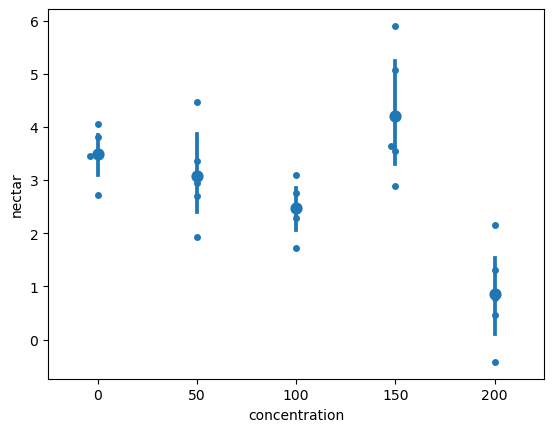

In [25]:
ax = sns.pointplot(data=nectar, y='nectar', x='concentration', linestyle='')
ax = sns.swarmplot(data=nectar, y='nectar', x='concentration');

- What are your initial thoughts about the data?

> It looks as if caffeine concentration up to 100μg does not have much affect on nectar taken, coming in at around 3g nectar. It then peaks at about 4g nectar for 150μg caffeine then falls to about 1g nectar at 200μg caffeine. This suggests that perhaps bees are insensitive to caffeine below about 150μg, that they avoid nectar that contains too much caffeine and that there is a sweet spot at about 150μg.

Normally, when the explanatory and response variables are both numerical we would perform a linear regression (as in the snake temperature in question 4). But in this case, because the relationship between nectar taken and caffeine concentration is not linear (i.e., not in a straight line), a linear regression is not appropriate. Instead we can use an ANOVA. This is similar to the *t*-test (which compares the means of two groups). An ANOVA compares the means of more than two groups.

The null hypothesis of an ANOVA is that the means of all groups are the same. So we are asking the question, what is compatibility of the data with the null hypothesis that mean nectar taken across all caffeine concentrations is the same?

Specifically for this dataset we will use a one-way ANOVA. All this means is that we have one explanatory variable, in this case caffeine concentration. There is also something called a two-way ANOVA if you have two explanatory variables. We won't consider that in this course.

The code to run a one-way ANOVA is very simple:

```python
from statsmodels.stats.oneway import anova_oneway

test = anova_oneway(df['response variable'], df['explanatory variable'], use_var='equal')

print(f'degrees of freedom = {test.df}')
print(f'F-statistic = {test.statistic:.2g}')
print(f'P = {test.pvalue:.2g}')
```

- the argument `use_var='equal'` tells the ANOVA test that you consider the variability in the data in each group is roughly the same. Looking at the spread of the data plotted above, this seems a reasonable assumption.
- ANOVAs use the *F*-statistic rather than the *t*-statistic. We don't need to worry about this. You just need this value when reporting the result.
- ANOVAs also have two values for the degrees of freedom rather than the one in the *t*-test, again this is only needed for reporting the result.
- ANOVAs do not give you 95% CIs. ANOVAs gives you evidence that things differ or not, they do not tell you by how much they differ.
- To report the result of an ANOVA you quote the value of the *F* statistic with the two degrees of freedom and the value of *P*. For example, *F*<sub>4,20</sub> = 10.5, *P* = 0.0001. 

---

- Perform a one-way ANOVA to measure the compatibility of the data with the null hypothesis that mean nectar taken across all caffeine concentrations is the same. 


<div class="alert alert-info">

Answer

- degrees of freedom = (4.0, 20.0)
- *F*-statistic = 10.5
- *P* = 9.5 x 10<sup>-5</sup>

</div>


In [26]:
test = anova_oneway(nectar['nectar'], nectar['concentration'], use_var='equal')

print(f'degrees of freedom = {test.df}')
print(f'F-statistic = {test.statistic:.3g}')
print(f'P = {test.pvalue:.2g}')

degrees of freedom = (4.0, 20.0)
F-statistic = 10.5
P = 9.5e-05


- What do you conclude about the effect of caffeine on bees feeding on nectar?

> The amount of nectar taken by bees differs significantly across the amount of caffeine the nectar contains (*F*<sub>4,20</sub> = 10.5, *P* = 0.0001).

An ANOVA measures the data's compatibility with the null hypothesis of *all* means being the same. So if you get a significant result (*P* < 0.05) you have evidence that at least one of the means is different from the others. But it does not tell you which one. Of course, you can just look at a plot of your data and take a guess. For example, you might think that nectar taken from the 200μg group is statistically significantly less than others, and that nectar taken from the 150μg is statistically significantly more than the others.

To determine which means are significantly different you need to perform a **pairwise comparison**. You compare all pairs of means, i.e., 0μg vs. 50μg, 0μg vs. 100μg, 0μg vs. 150μg, and so on.  We will have to leave this until next week when we look at multiple testing.

<div class="alert alert-success">

Concepts to take away from this question.

1. Use ANOVAs when you want to compare the means of more than two groups.
2. An ANOVA measures the compatibility of the data with the null hypothesis that all means are equal.
3. An ANOVA that gives a significant result tells you that at least one of your groups is significantly different. It doesn't tell you which ones, nor does it tell you how much they differ.
</div>


# Class 10 homework: Correlation, correlation matrix, correlation heatmap

See [Class_10_homework](Class_10_homework.ipynb) for details.